# TP4 – Workflow Machine Learning à grande échelle : Full Body Checkup Lab avec Spark

## Ma contribution

**Le notebook est-il correct ?** Oui : toutes les cellules ont été exécutées de bout en bout, sans erreur (sorties incluses ; Spark 3.5.3 en `local[*]`, 6 Go pour le driver). Ce notebook est issu du découpage du TP « Kaggle » en deux ; seul le texte a été modifié depuis l'exécution.

**Problèmes rencontrés**
- Fuite de données : `fasting_glucose`, `fbs`, `plbs`, `pp_glucose`, `eag` et `hba1c` (qui définit la cible) sont exclus des variables explicatives.
- Un même patient apparaît dans les 12 mois : le découpage train/test se fait par patient (hash de `MedID`) et non par ligne.
- La colonne `Zender` a 6 variantes à harmoniser ; l'imputation est faite dans le pipeline, après le split.
- Signal modeste (AUC 0,687) : sans les mesures de glycémie, les autres analyses expliquent mal l'HbA1c ; données (semi-)synthétiques.
- Sous Windows, Spark exige `winutils.exe` et `hadoop.dll`.

**Modifications / ajouts** : lecture parallèle des 12 CSV, jointure avec le profil patient, EDA en Spark SQL, export Parquet, pipeline MLlib, comparaison de 3 modèles (régression logistique, forêt aléatoire, GBT), sauvegarde du `PipelineModel` et script de scoring batch `score_checkup.py`.

**Autres informations** : meilleur modèle = régression logistique (AUC test 0,687, accuracy 0,737). Données Kaggle (~430 Mo) non versionnées (`checkup_data/`).

---

Workflow : **Data → EDA → Prétraitement → Transformation → ML → Évaluation → Déploiement**

Jeu de données : [Full Body Checkup Lab](https://www.kaggle.com/datasets/opendataforresearch/full-body-checkup-lab-dataset) (~250 000 bilans × 109 colonnes, 12 CSV ≈ 430 Mo), traité avec PySpark (DataFrame, SQL, MLlib) et Parquet.

Les CSV sont attendus dans `checkup_data/` (non versionné, cf. `.gitignore`).

In [1]:
import os, glob, warnings, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
os.makedirs("models", exist_ok=True)

# Full Body Checkup Lab avec Spark

**Pourquoi Spark ?** 12 fichiers mensuels (Août 2018 → Juillet 2019) × ~20 800 bilans × 109 analyses, soit ~430 Mo de CSV :
on lit tous les fichiers en parallèle (partitions), on stocke en **Parquet** (format colonnaire, standard de l'écosystème Hadoop/HDFS) et on
entraîne avec **MLlib**. En cluster il suffirait de remplacer `local[*]` par YARN et `checkup_data/` par un chemin `hdfs://…`.

**Problème** : prédire le **pré-diabète/diabète** (`hba1c ≥ 5,7 %`) à partir des *autres* analyses et du profil du patient.
Les variables directement liées à la glycémie (`fasting_glucose, fbs, plbs, pp_glucose, eag`) sont **exclues** : sinon on ne ferait que retrouver la cible (fuite de données).

## Data
Lecture parallèle des 12 CSV mensuels et du profil patient.

In [9]:
from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder.master("local[*]").appName("TP4-Checkup")
         .config("spark.driver.memory", "6g").config("spark.sql.shuffle.partitions", "16")
         .config("spark.sql.legacy.timeParserPolicy", "LEGACY").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
files = sorted(f for f in glob.glob("checkup_data/*.csv") if "SubjectDetails" not in f)
print(len(files), "fichiers mensuels :", [os.path.basename(f) for f in files])
labs = spark.read.csv(files, header=True, inferSchema=True)
subj = spark.read.csv("checkup_data/SubjectDetails.csv", header=True, inferSchema=True)
print("bilans :", labs.count(), "x", len(labs.columns), "| patients :", subj.count(), "| partitions :", labs.rdd.getNumPartitions())

12 fichiers mensuels : ['Apr19.csv', 'Aug18.csv', 'Dec18.csv', 'Feb19.csv', 'Jan19.csv', 'Jul19.csv', 'Jun19.csv', 'Mar19.csv', 'May19.csv', 'Nov18.csv', 'Oct18.csv', 'Sep18.csv']


bilans : 250164 x 109 | patients : 20847 | partitions : 12


## EDA

In [10]:
labs = labs.withColumn("month", F.date_format(F.to_date("Collected Dt", "d MMMM yyyy"), "yyyy-MM"))
labs.createOrReplaceTempView("labs"); subj.createOrReplaceTempView("subj")
spark.sql("SELECT month, COUNT(*) n, ROUND(AVG(hba1c),3) hba1c_moy, ROUND(AVG(fasting_glucose),1) gly_moy, ROUND(AVG(systolic_bp),1) tas_moy FROM labs GROUP BY month ORDER BY month").show()
spark.sql("SELECT Zender, COUNT(*) n FROM subj GROUP BY Zender ORDER BY n DESC").show()
spark.sql("SELECT Diet, COUNT(*) n FROM subj GROUP BY Diet ORDER BY n DESC").show()

+-------+-----+---------+-------+-------+
|  month|    n|hba1c_moy|gly_moy|tas_moy|
+-------+-----+---------+-------+-------+
|   NULL|41694|    5.403|   92.0|  118.2|
|2018-08|20847|    5.404|   92.0|  118.2|
|2018-09|20847|    5.397|   91.9|  118.0|
|2018-11|20847|    5.396|   91.9|  118.2|
|2018-12|20847|      5.4|   91.9|  118.0|
|2019-01|20847|    5.399|   92.0|  118.3|
|2019-03|20847|    5.398|   91.8|  118.2|
|2019-04|20847|      5.4|   92.0|  118.1|
|2019-05|20847|    5.396|   91.9|  118.0|
|2019-06|20847|    5.408|   92.2|  118.1|
|2019-07|20847|    5.401|   92.0|  118.0|
+-------+-----+---------+-------+-------+



+------+-----+
|Zender|    n|
+------+-----+
|  Male|10215|
|Female| 9113|
|  TrFe|  754|
|  PNTD|  511|
|    NS|  250|
|TrMale|    4|
+------+-----+



+------+----+
|  Diet|   n|
+------+----+
|   Veg|8381|
|NonVeg|7287|
|    NS|2618|
|  PNTD|1516|
| Vegan|1045|
+------+----+



Colonnes avec valeurs manquantes :
month    41694
Name: 0, dtype: int64


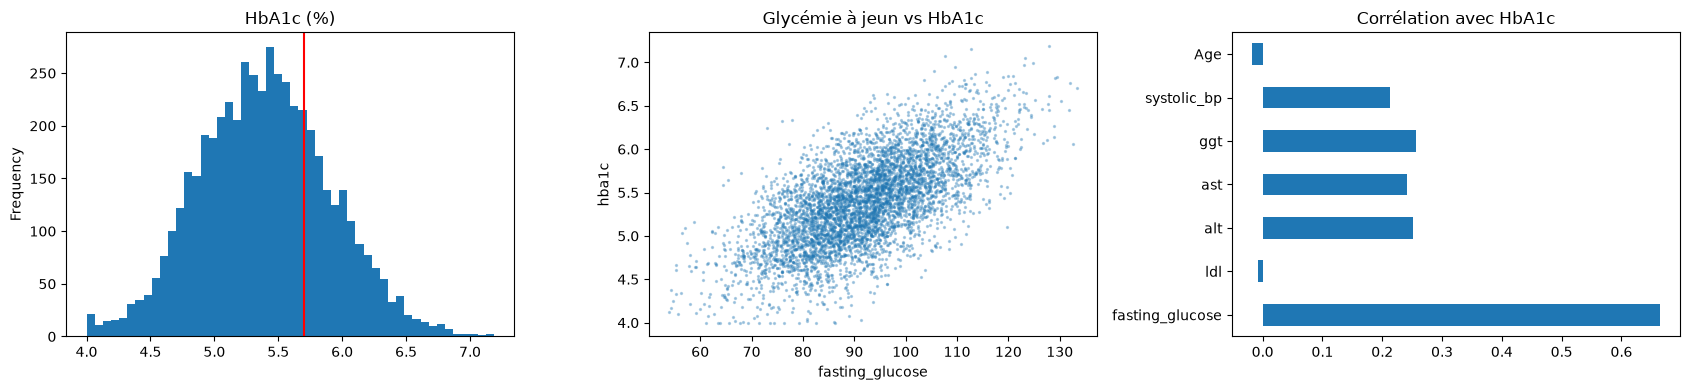

In [11]:
nulls = labs.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in labs.columns]).toPandas().T[0]
print("Colonnes avec valeurs manquantes :"); print(nulls[nulls > 0].sort_values(ascending=False).head(10))
# échantillon (2 %) ramené côté pandas pour les graphiques
smp = labs.join(subj.select("MedID","Age"), "MedID").sample(0.02, seed=1).select("hba1c","fasting_glucose","ldl","alt","ast","ggt","systolic_bp","Age").toPandas()
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
smp.hba1c.plot.hist(bins=50, ax=ax[0], title="HbA1c (%)"); ax[0].axvline(5.7, c="r")
smp.plot.scatter("fasting_glucose", "hba1c", s=2, alpha=.3, ax=ax[1], title="Glycémie à jeun vs HbA1c")
smp.corr()["hba1c"].drop("hba1c").plot.barh(ax=ax[2], title="Corrélation avec HbA1c"); plt.tight_layout(); plt.show()

## Prétraitement

Jointure bilan ↔ patient (`MedID`), harmonisation de la colonne `Zender` (6 variantes), création de la cible, suppression des variables fuyantes et
des identifiants. Le jeu nettoyé est écrit en **Parquet** ; l'imputation des manquants (médiane) se fait dans le pipeline (étape Transformation).

In [12]:
subj.groupBy("Zender").count().show()
sub = (subj.select("MedID", "Age", F.col("Reg Weight").alias("weight"), "Diet", "Smoking", "Drinking",
        F.when(F.lower(F.col("Zender")).startswith("m"), "Male").when(F.lower(F.col("Zender")).startswith("f"), "Female").otherwise("Other").alias("sex")))
df = labs.join(sub, "MedID").withColumn("label", (F.col("hba1c") >= 5.7).cast("double")).where(F.col("hba1c").isNotNull())
leak = ["hba1c", "eag", "fasting_glucose", "fbs", "plbs", "pp_glucose"]
ids = ["MedID", "Sample ID", "Collected From", "Collected Dt", "Collected Tm", "Reported Time", "month"]
num_cols = [c for c, t in df.dtypes if t in ("int", "bigint", "double") and c not in leak + ids + ["label"]]
cat_cols = ["sex", "Diet", "Smoking", "Drinking"]
df = df.select("MedID", "label", *num_cols, *cat_cols)
print(len(num_cols), "variables numériques,", len(cat_cols), "catégorielles")
df.groupBy("label").count().show()
df.write.mode("overwrite").parquet("checkup_clean.parquet")
df = spark.read.parquet("checkup_clean.parquet").cache(); print("lignes :", df.count())

+------+-----+
|Zender|count|
+------+-----+
|TrMale|    4|
|    NS|  250|
|  Male|10215|
|  TrFe|  754|
|  PNTD|  511|
|Female| 9113|
+------+-----+



85 variables numériques, 4 catégorielles


+-----+------+
|label| count|
+-----+------+
|  1.0| 68552|
|  0.0|181612|
+-----+------+



lignes : 250164


**Séparation train/test par patient** : un même patient apparaît dans les 12 mois ; un split aléatoire par ligne mettrait le même patient
des deux côtés et gonflerait les scores. On découpe donc sur un hash de `MedID`.

In [13]:
bucket = F.abs(F.hash("MedID")) % 100
train, test = df.where(bucket < 80), df.where(bucket >= 80)
print("train :", train.count(), "| test :", test.count())

train : 200148 | test : 50016


## Transformation

`Imputer` (médiane) → `StringIndexer` + `OneHotEncoder` → `VectorAssembler` → `StandardScaler`.

In [14]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
imputed = [c + "_imp" for c in num_cols]
stages = [Imputer(inputCols=num_cols, outputCols=imputed, strategy="median"),
          StringIndexer(inputCols=cat_cols, outputCols=[c + "_idx" for c in cat_cols], handleInvalid="keep"),
          OneHotEncoder(inputCols=[c + "_idx" for c in cat_cols], outputCols=[c + "_oh" for c in cat_cols]),
          VectorAssembler(inputCols=imputed + [c + "_oh" for c in cat_cols], outputCol="raw"),
          StandardScaler(inputCol="raw", outputCol="features", withMean=False)]

## ML

Régression logistique, forêt aléatoire et GBT (MLlib), entraînés en parallèle sur les partitions.

In [15]:
import time
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
algos = {"LogReg": LogisticRegression(labelCol="label", featuresCol="features", maxIter=50),
         "RandomForest": RandomForestClassifier(labelCol="label", featuresCol="features", numTrees=60, maxDepth=7, seed=42),
         "GBT": GBTClassifier(labelCol="label", featuresCol="features", maxIter=30, maxDepth=5, seed=42)}
auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")
fitted, res = {}, []
for name, algo in algos.items():
    t = time.time(); m = Pipeline(stages=stages + [algo]).fit(train); fitted[name] = m
    res.append((name, round(auc.evaluate(m.transform(test)), 4), round(time.time() - t, 1)))
pd.DataFrame(res, columns=["modèle", "AUC test", "temps (s)"])

,modèle,AUC test,temps (s)
0,LogReg,0.6871,57.5
1,RandomForest,0.6552,53.7
2,GBT,0.6852,68.6


## Éval

In [16]:
best_name = max(res, key=lambda r: r[1])[0]; best = fitted[best_name]; pred = best.transform(test)
print("Meilleur modèle :", best_name)
for m in ["accuracy", "f1", "weightedPrecision", "weightedRecall"]:
    print(f"{m:18s}", round(MulticlassClassificationEvaluator(labelCol="label", metricName=m).evaluate(pred), 4))
cm = pred.groupBy("label", "prediction").count().toPandas().pivot(index="label", columns="prediction", values="count")
print("Matrice de confusion (lignes = réel, colonnes = prédit) :"); print(cm)
print("Prévalence de la classe positive (test) :", round(test.agg(F.avg("label")).first()[0], 3))
# importance des variables numériques (modèles à base d'arbres)
if best_name != "LogReg":
    fi = best.stages[-1].featureImportances.toArray()
    pd.Series(fi[:len(num_cols)], index=num_cols).sort_values().tail(12).plot.barh(title=f"Importance des variables ({best_name})"); plt.show()

Meilleur modèle : LogReg


accuracy           0.737


f1                 0.6764


weightedPrecision  0.7017


weightedRecall     0.737


Matrice de confusion (lignes = réel, colonnes = prédit) :
prediction    0.0   1.0
label                  
0.0         34792  1535
1.0         11618  2071


Prévalence de la classe positive (test) : 0.274


**Lecture** : l'AUC et le F1 se lisent par rapport à la prévalence de la classe positive (un classifieur constant aurait AUC = 0,5 et une accuracy égale à la
fréquence de la classe majoritaire).

**Résultat** : AUC ≈ 0,69 (régression logistique et GBT), la forêt aléatoire fait moins bien (0,66). Le signal est modeste : sans les mesures de glycémie, les autres analyses expliquent mal l'HbA1c (prévalence positive ≈ 27 %, accuracy 0,74 pour un classifieur constant à 0,73). Le gain du Big Data ici est de pouvoir le démontrer rapidement sur 250 000 lignes, pas d'obtenir un modèle clinique.

## Déploiement

Sauvegarde du `PipelineModel` complet (format Spark, stockable sur HDFS), rechargement, et scoring d'un nouveau lot de patients (batch) – cf. `score_checkup.py`.

In [17]:
best.write().overwrite().save("models/checkup_spark_model")
from pyspark.ml import PipelineModel
loaded_model = PipelineModel.load("models/checkup_spark_model")
from pyspark.ml.functions import vector_to_array
loaded_model.transform(test.limit(5)).select("MedID", "label", F.round(vector_to_array("probability")[1], 3).alias("proba_prediabete"), "prediction").show()

+------+-----+----------------+----------+
| MedID|label|proba_prediabete|prediction|
+------+-----+----------------+----------+
|100148|  1.0|           0.338|       0.0|
|100499|  1.0|           0.178|       0.0|
|100603|  0.0|           0.235|       0.0|
|100700|  1.0|           0.127|       0.0|
|100767|  0.0|           0.407|       0.0|
+------+-----+----------------+----------+



## Conclusion

# Conclusion

| | Résultat |
|---|---|
| Données | ~250 000 bilans × 109 colonnes, 12 CSV |
| Lecture | `spark.read.csv` parallélisé par partitions, stockage Parquet |
| Pipeline | `Pipeline` MLlib (Imputer → Indexer → Assembler → Scaler) |
| Déploiement | `PipelineModel.save` + `score_checkup.py` (scoring batch) |

Points d'attention : **fuite de données** (variables glycémiques), **déséquilibre de classes**, et **split par patient** plutôt que par ligne.
Limite : les données du bilan semblent (semi-)synthétiques ; les scores ne préjugent donc pas d'une valeur clinique réelle.